# Dong et al. 2020 — Prostate Cancer — Step 02: EMT-TF Expression

**Unconditional step** (`01_task.md` §2): the EMT transcription-factor readout is always produced as the final notebook, outside the gate chain. Because **Gate 1 was NO-GO** (the malignant compartment is neither sample-integrated nor a single continuous manifold — see `01_preprocessing`), no trajectory was fit; this is notebook **02** (renumbered per `01_task.md` §6: Gate 1 NO-GO → 01 + expression).

**Method (derived + shown, `02_train.md` C1–C4).** From a candidate EMT-TF panel spanning the Snail / Zeb / Twist families **plus** the FOXC and PRRX mesenchymal families (`03_eval.md` fork 5; VIM is a mesenchymal marker, **not** a TF, so it is excluded — `04_test.md` Chen), we keep factors with detectable expression and overlay the thresholded expressers on the grey manifold as a categorical plot (reference style, not a continuous single-gene colormap — `04_test.md` Sun).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = 'Dong2020_Prostate-3'
pth = os.path.join(*(['..']*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', 'Prostate', name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Prostate', name)
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
print(adata.n_obs, 'malignant cells |', adata.obs.celltype.value_counts().to_dict())

9698 malignant cells | {'Adeno': 4933, 'NEPC': 4765}


## Screen the candidate EMT-TF panel (gated on detectable expression)

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('absent from data:', [g for g in panel if g not in adata.var_names])
X = sc.get.obs_df(adata, keys=present+['celltype'])
rows=[]
for g in present:
    v=X[g].values; adeno=X.loc[X.celltype=='Adeno',g]; nepc=X.loc[X.celltype=='NEPC',g]
    rows.append((g, round(100*(v>0).mean(),1), round(v[v>0].mean() if (v>0).any() else 0,2),
                 round(100*(adeno>0).mean(),1), round(100*(nepc>0).mean(),1)))
scr = pd.DataFrame(rows, columns=['TF','pct_expr','mean_in_expr','pct_adeno','pct_nepc']).sort_values('pct_expr', ascending=False)
print(scr.to_string(index=False))

absent from data: ['FOXC2']
    TF  pct_expr  mean_in_expr  pct_adeno  pct_nepc
TWIST1      26.8          1.10       51.3       1.3
 SNAI1       6.0          0.53       10.2       1.7
 PRRX2       3.5          0.47        6.6       0.3
 FOXC1       3.5          0.47        5.1       1.8
TWIST2       3.5          0.45        6.9       0.1
  ZEB2       2.4          0.47        4.1       0.6
  ZEB1       2.3          0.44        4.1       0.5
 SNAI2       2.0          0.47        3.2       0.7
 PRRX1       1.5          0.49        2.3       0.6


**Readout.** The EMT program is almost entirely confined to the **adenocarcinoma** lobe. **TWIST1** is the dominant factor (expressed in ~51% of adeno cells, near-absent in NEPC), followed by **SNAI1** (Snail family) and the widened-panel factors **FOXC1 / PRRX2 / TWIST2**. We display the three most informative factors spanning distinct families — TWIST1, SNAI1, FOXC1 — as a categorical overlay.

## EMT-TF expression overlay (deliverable)

Thresholded expressers of each TF are overlaid in a distinct color on the grey malignant manifold (reference categorical style). Thresholds are per-gene: TWIST1 at the median of its positive values (strong expressers), SNAI1 and FOXC1 at detection (>0), since they are sparsely expressed.

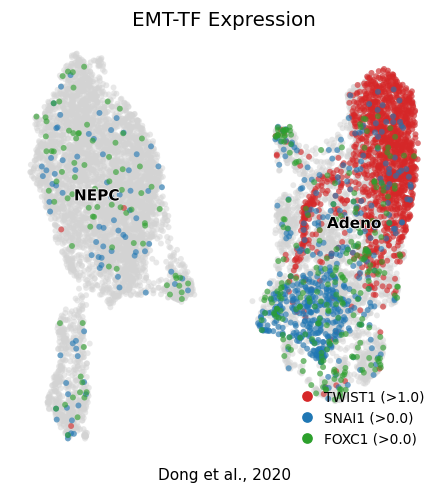

In [4]:
g_plt = {'TWIST1': ('tab:red', 1.0),
         'SNAI1' : ('tab:blue', 0.0),
         'FOXC1' : ('tab:green', 0.0)}
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=60, alpha=.5, frameon=False, show=False, ax=ax)
for var,(col,thr) in g_plt.items():
    sub = adata[adata[:, var].X > thr].copy()
    sc.pl.umap(sub, na_color=col, size=60, alpha=.6, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=60, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
import matplotlib.lines as mlines
handles=[mlines.Line2D([],[],marker='o',ls='',color=c,label=f'{v} (>{t})') for v,(c,t) in g_plt.items()]
ax.legend(handles=handles, frameon=False, loc='lower right', handletextpad=.25, fontsize=9)
ax.set_title('EMT-TF Expression', size=13)
ax.text(.5, -.05, 'Dong et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
plt.show()

## Summary

The mesenchymal / EMT-TF program in this dataset is carried by **TWIST1** (dominant), with sparser **SNAI1** and **FOXC1**, and is essentially restricted to the **adenocarcinoma** lobe; the small-cell **NEPC** lobe expresses almost none of these factors. This is consistent with the Gate-1 finding that the malignant compartment comprises two distinct lineages that neither integrate nor form a single continuous developmental manifold.